In [2]:
import pandas as pd
from pgmpy.models import BayesianNetwork
from pgmpy.estimators import MaximumLikelihoodEstimator, HillClimbSearch, BicScore
from pgmpy.inference import VariableElimination
from sklearn.metrics import accuracy_score, roc_auc_score, log_loss, brier_score_loss
from sklearn.model_selection import train_test_split
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
import time


In [3]:
# Load the Parkinson's dataset
file_path = 'assessment-item1\parkinsons_data-VOICE-features.xlsx'
parkinsons_df = pd.read_excel(file_path)

# Display the first few rows and general info
print(parkinsons_df.head())
print(parkinsons_df.info())

             name  MDVP:Fo(Hz)  MDVP:Fhi(Hz)  MDVP:Flo(Hz)  MDVP:Jitter(%)  \
0  phon_R01_S01_1      119.992       157.302        74.997         0.00784   
1  phon_R01_S01_2      122.400       148.650       113.819         0.00968   
2  phon_R01_S01_3      116.682       131.111       111.555         0.01050   
3  phon_R01_S01_4      116.676       137.871       111.366         0.00997   
4  phon_R01_S01_5      116.014       141.781       110.655         0.01284   

   MDVP:Jitter(Abs)  MDVP:RAP  MDVP:PPQ  Jitter:DDP  MDVP:Shimmer  ...  \
0           0.00007   0.00370   0.00554     0.01109       0.04374  ...   
1           0.00008   0.00465   0.00696     0.01394       0.06134  ...   
2           0.00009   0.00544   0.00781     0.01633       0.05233  ...   
3           0.00009   0.00502   0.00698     0.01505       0.05492  ...   
4           0.00011   0.00655   0.00908     0.01966       0.06425  ...   

   Shimmer:DDA      NHR     HNR  status      RPDE       DFA   spread1  \
0      0.0654

In [4]:
# Drop irrelevant columns
parkinsons_df = parkinsons_df.drop(columns=['name'], errors='ignore')


In [5]:
# Ensure 'status' is treated as a binary target variable
parkinsons_df['status'] = parkinsons_df['status'].astype(int)


In [6]:
# Discretize with Quantile Binning to Ensure Even Distribution
for column in parkinsons_df.columns:
    if column != 'status':
        parkinsons_df[column] = pd.qcut(parkinsons_df[column], q=10, labels=False, duplicates='drop')

In [7]:
# Split data into training and testing sets
train_df, test_df = train_test_split(parkinsons_df, test_size=0.2, stratify=parkinsons_df['status'], random_state=42)


In [8]:
# Re-run structure learning with Bayesian Information Criterion
hc = HillClimbSearch(train_df)
best_model = hc.estimate(scoring_method=BicScore(train_df))
learned_structure = BayesianNetwork(best_model.edges())

  0%|          | 0/1000000 [00:00<?, ?it/s]

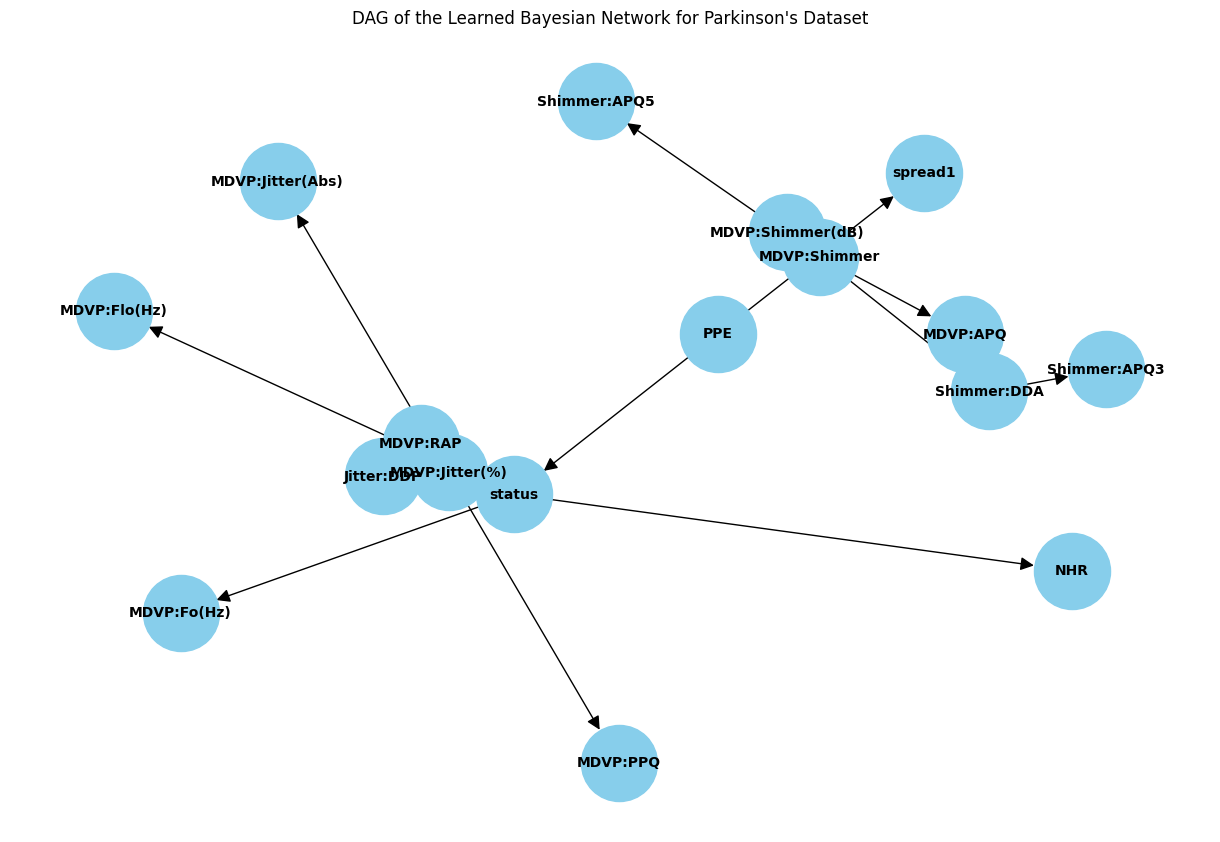

In [9]:
# Plotting the learned Bayesian Network structure (DAG)
plt.figure(figsize=(12, 8))
G = nx.DiGraph()
G.add_edges_from(learned_structure.edges())

# Draw the graph
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_size=3000, node_color="skyblue", font_size=10, font_weight="bold", arrowsize=20)
plt.title("DAG of the Learned Bayesian Network for Parkinson's Dataset")
plt.show()

In [10]:
# Add missing nodes carefully and avoid manual connections to 'status'
missing_nodes = set(parkinsons_df.columns) - set(learned_structure.nodes())
print("Missing nodes in the structure:", missing_nodes)

Missing nodes in the structure: {'DFA', 'D2', 'spread2', 'MDVP:Fhi(Hz)', 'RPDE', 'HNR'}


In [11]:
# Fit the model with Maximum Likelihood Estimation (MLE) on the learned structure
for node in missing_nodes:
    learned_structure.add_node(node)

# Re-fit the model with maximum likelihood estimation on the adjusted structure
learned_structure.fit(train_df, estimator=MaximumLikelihoodEstimator)

# Update inference with the new learned structure
learned_inference = VariableElimination(learned_structure)

In [12]:
# # Initialize inference on the learned model
# learned_inference = VariableElimination(learned_structure)

In [13]:
# Check all CPDs in the learned model to identify any sparsity or missing data
print("Available CPDs in learned structure:")
for cpd in learned_structure.get_cpds():
    print(cpd)

Available CPDs in learned structure:
+-------------------+-------------+-----+---------------------+
| MDVP:RAP          | MDVP:RAP(0) | ... | MDVP:RAP(9)         |
+-------------------+-------------+-----+---------------------+
| MDVP:Jitter(%)(0) | 0.75        | ... | 0.0                 |
+-------------------+-------------+-----+---------------------+
| MDVP:Jitter(%)(1) | 0.1875      | ... | 0.0                 |
+-------------------+-------------+-----+---------------------+
| MDVP:Jitter(%)(2) | 0.0         | ... | 0.0                 |
+-------------------+-------------+-----+---------------------+
| MDVP:Jitter(%)(3) | 0.0625      | ... | 0.0                 |
+-------------------+-------------+-----+---------------------+
| MDVP:Jitter(%)(4) | 0.0         | ... | 0.0                 |
+-------------------+-------------+-----+---------------------+
| MDVP:Jitter(%)(5) | 0.0         | ... | 0.0                 |
+-------------------+-------------+-----+---------------------+
| M

In [14]:
# # Step 1: Define missing nodes and add them to the structure with connections to 'status'
# missing_nodes = { 'DFA','NHR', 'RPDE'}


In [15]:
# # Add each missing node and connect it to 'status'
# for node in missing_nodes:
#     if not learned_structure.has_node(node):
#         learned_structure.add_node(node)
#     if not learned_structure.has_edge(node, 'status'):
#         learned_structure.add_edge(node, 'status')  # Connect each node to 'status'

In [16]:
# # Plot the updated structure to verify connections (optional)
# plt.figure(figsize=(12, 8))
# G = nx.DiGraph()
# G.add_edges_from(learned_structure.edges())
# pos = nx.spring_layout(G)
# nx.draw(G, pos, with_labels=True, node_size=3000, node_color="skyblue", font_size=10, font_weight="bold", arrowsize=20)
# plt.title("Updated DAG of the Learned Bayesian Network for Parkinson's Dataset")
# plt.show()


In [17]:
# # Step 2: Re-fit the model with the updated structure
# learned_structure.fit(train_df, estimator=MaximumLikelihoodEstimator)

# # Step 3: Re-initialize the inference engine with the updated model
# learned_inference = VariableElimination(learned_structure)


In [18]:
# Model Evaluation
y_true = test_df['status'].values
y_pred = []
y_proba = []

start_train_time = time.time()
learned_structure.fit(train_df)
train_time = time.time() - start_train_time

# Start testing time
start_test_time = time.time()
for _, row in test_df.iterrows():
    # Prepare evidence dictionary from the row excluding 'status'
    evidence = {col: row[col] for col in test_df.columns if col != 'status'}
    
    try:
        query_result = learned_inference.query(variables=['status'], evidence=evidence)
        prob = query_result.values[1]  # Probability of status=1 (Parkinson's)
        y_proba.append(prob)
        y_pred.append(1 if prob >= 0.5 else 0)
    except KeyError as e:
        print(f"KeyError for evidence {evidence}: {e}")
        y_proba.append(np.nan)  # Append NaN for failed predictions
        y_pred.append(np.nan)

test_time = time.time() - start_test_time

# Convert y_proba to a numpy array for easier handling of NaNs
y_proba = np.array(y_proba)
y_pred = np.array(y_pred)

# Check for NaNs in y_proba and handle them
if np.isnan(y_proba).any():
    print("NaN values found in y_proba; replacing NaNs with a default probability of 0.5")
    y_proba = np.nan_to_num(y_proba, nan=0.5)  # Replace NaNs with 0.5
    y_pred = np.nan_to_num(y_pred, nan=0)      # Replace NaNs in predictions with 0

# Calculate Metrics
accuracy = accuracy_score(y_true[~np.isnan(y_pred)], y_pred[~np.isnan(y_pred)])
auc_score = roc_auc_score(y_true, y_proba)
kl_divergence = log_loss(y_true, y_proba)  # Log Loss approximates KL Divergence in binary classification
brier_score = brier_score_loss(y_true, y_proba)

NaN values found in y_proba; replacing NaNs with a default probability of 0.5


c:\Users\msi 1\AppData\Local\Programs\Python\Python311\Lib\site-packages\pgmpy\factors\discrete\DiscreteFactor.py:489: RuntimeWarning: invalid value encountered in divide
  phi.values = phi.values / phi.values.sum()


In [19]:
# Print Results
print("Model Evaluation Metrics for Parkinson's Bayesian Network with Hill Climb Structure Learning:")
print(f"Accuracy: {accuracy:.4f}")
print(f"AUC: {auc_score:.4f}")
print(f"Kullback-Leibler Divergence (Log Loss): {kl_divergence:.4f}")
print(f"Brier Score: {brier_score:.4f}")
print(f"Testing Time: {test_time:.4f} seconds")
print(f"Training Time: {train_time:.4f} seconds")


Model Evaluation Metrics for Parkinson's Bayesian Network with Hill Climb Structure Learning:
Accuracy: 0.8462
AUC: 0.8448
Kullback-Leibler Divergence (Log Loss): 2.0424
Brier Score: 0.1195
Testing Time: 0.0340 seconds
Training Time: 0.0625 seconds


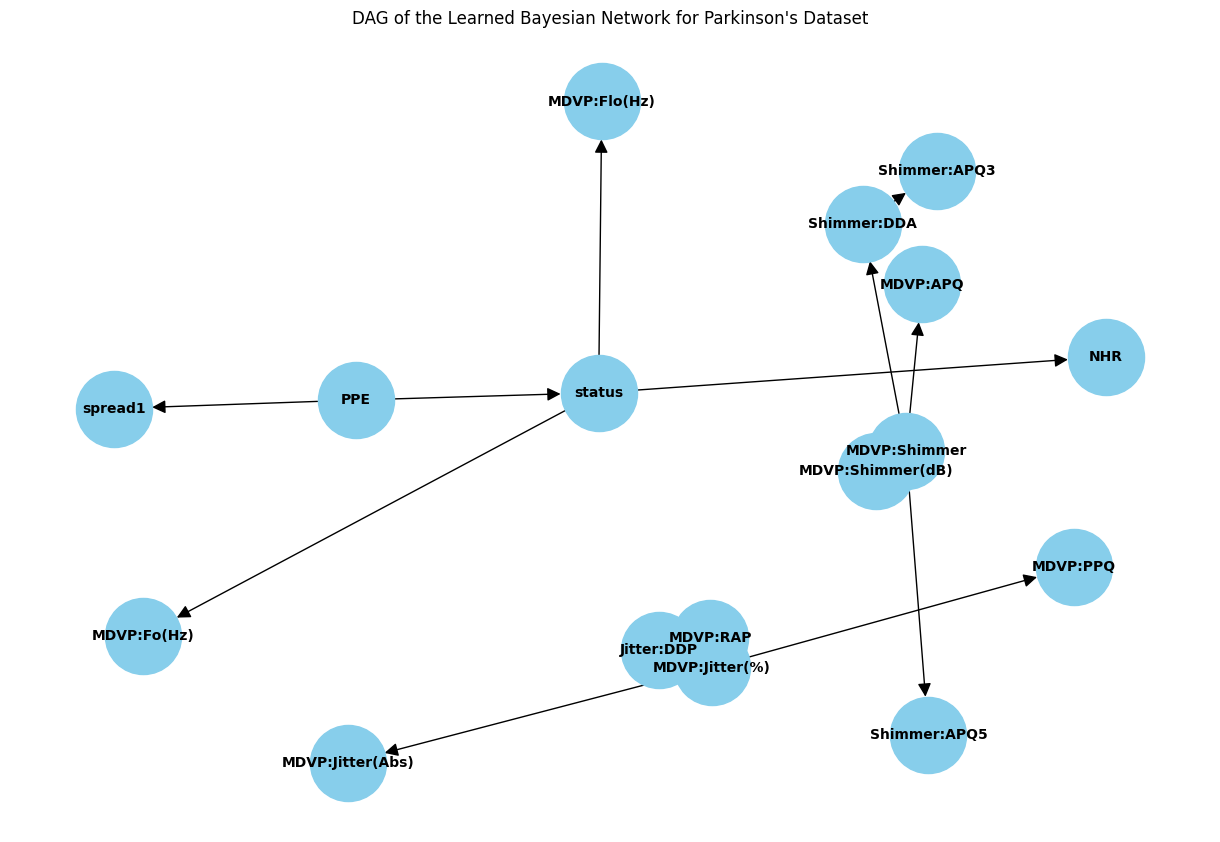

In [20]:
# Plotting the learned Bayesian Network structure (DAG)
plt.figure(figsize=(12, 8))
G = nx.DiGraph()
G.add_edges_from(learned_structure.edges())

# Draw the graph
pos = nx.spring_layout(G)
nx.draw(G, pos, with_labels=True, node_size=3000, node_color="skyblue", font_size=10, font_weight="bold", arrowsize=20)
plt.title("DAG of the Learned Bayesian Network for Parkinson's Dataset")
plt.show()

In [21]:

# # Define and modify structure with domain knowledge
# learned_structure = BayesianNetwork(best_model.edges())

# # Convert to networkx graph to check for paths
# graph_nx = nx.DiGraph(learned_structure.edges())

# # Manual edges to add relationships without loops
# manual_edges = [('MDVP:Fo(Hz)', 'status'), ('NHR', 'status'), ('MDVP:Shimmer', 'status')]
# for edge in manual_edges:
#     if not graph_nx.has_edge(*edge) and not nx.has_path(graph_nx, edge[1], edge[0]):
#         learned_structure.add_edge(*edge)
#         graph_nx.add_edge(*edge)  # Update the networkx graph as well
#     else:
#         print(f"Skipping edge {edge} to avoid loop.")


In [22]:
# Define quantile-based bins for each feature with increased precision
mdvp_fo_bins = pd.qcut(parkinsons_df['MDVP:Fo(Hz)'], q=10, retbins=True, duplicates='drop')[1]
mdvp_fhi_bins = pd.qcut(parkinsons_df['MDVP:Fhi(Hz)'], q=10, retbins=True, duplicates='drop')[1]
mdvp_flo_bins = pd.qcut(parkinsons_df['MDVP:Flo(Hz)'], q=10, retbins=True, duplicates='drop')[1]
mdvp_jitter_bins = pd.qcut(parkinsons_df['MDVP:Jitter(%)'], q=10, retbins=True, duplicates='drop')[1]
mdvp_jitter_abs_bins = pd.qcut(parkinsons_df['MDVP:Jitter(Abs)'], q=10, retbins=True, duplicates='drop')[1]
mdvp_rap_bins = pd.qcut(parkinsons_df['MDVP:RAP'], q=10, retbins=True, duplicates='drop')[1]
mdvp_ppq_bins = pd.qcut(parkinsons_df['MDVP:PPQ'], q=10, retbins=True, duplicates='drop')[1]
jitter_ddp_bins = pd.qcut(parkinsons_df['Jitter:DDP'], q=10, retbins=True, duplicates='drop')[1]
mdvp_shimmer_bins = pd.qcut(parkinsons_df['MDVP:Shimmer'], q=10, retbins=True, duplicates='drop')[1]
mdvp_shimmer_db_bins = pd.qcut(parkinsons_df['MDVP:Shimmer(dB)'], q=10, retbins=True, duplicates='drop')[1]
shimmer_apq3_bins = pd.qcut(parkinsons_df['Shimmer:APQ3'], q=10, retbins=True, duplicates='drop')[1]
shimmer_apq5_bins = pd.qcut(parkinsons_df['Shimmer:APQ5'], q=10, retbins=True, duplicates='drop')[1]
mdvp_apq_bins = pd.qcut(parkinsons_df['MDVP:APQ'], q=10, retbins=True, duplicates='drop')[1]
shimmer_dda_bins = pd.qcut(parkinsons_df['Shimmer:DDA'], q=10, retbins=True, duplicates='drop')[1]
nhr_bins = pd.qcut(parkinsons_df['NHR'], q=10, retbins=True, duplicates='drop')[1]
hnr_bins = pd.qcut(parkinsons_df['HNR'], q=10, retbins=True, duplicates='drop')[1]


In [23]:
def get_bin(value, bins):
    bin_index = pd.cut([value], bins=bins, labels=False)[0]
    if pd.isna(bin_index):  # Handle values outside the bin range
        bin_index = 0 if value < bins[0] else len(bins) - 2  # Use nearest bin index
    return int(bin_index)

In [24]:
# # Print all available CPDs in the learned structure
# print("Available CPDs in learned structure:")
# for cpd in learned_structure.get_cpds():
#     print(cpd)


In [25]:
# Adjust evidence function with improved error handling for missing CPDs
def adjust_evidence(evidence, model):
    adjusted_evidence = {}
    for feature, value in evidence.items():
        if model.has_node(feature):
            cpd = model.get_cpds(feature)
            if cpd is not None:
                max_state = cpd.get_cardinality([feature])[feature] - 1
                adjusted_evidence[feature] = min(value, max_state)
            else:
                print(f"CPD for {feature} missing.")
        else:
            print(f"{feature} not found in model.")
    return adjusted_evidence


In [26]:
def run_query(evidence_values):
    # Convert continuous values to bins for each feature and create evidence dictionary
    initial_evidence = {feature: value for feature, value, _ in evidence_values}
    query_evidence = {feature: get_bin(value, bins) for feature, value, bins in evidence_values}
    query_evidence = adjust_evidence(query_evidence, learned_structure)
    
    print("Initial Evidence:", initial_evidence)
    print("Binned Evidence:", query_evidence)
    print("Adjusted Evidence:", query_evidence)

    # Run the query and handle potential KeyErrors
    try:
        query_result = learned_inference.query(variables=['status'], evidence=query_evidence)
        # Print conditional probability results
        print("Conditional Probability for status given the evidence:")
        for state, prob in zip(query_result.state_names['status'], query_result.values):
            print(f"P(status = {state} | evidence) = {prob:.4f}")
    except KeyError as e:
        print(f"KeyError for evidence {query_evidence}: {e}")


In [27]:
# Evidence for Query 3
query3_values = [
    ('MDVP:Fo(Hz)', 197.076, mdvp_fo_bins),
    ('MDVP:Fhi(Hz)', 206.896, mdvp_fhi_bins),
    ('MDVP:Flo(Hz)', 192.055, mdvp_flo_bins),
    ('MDVP:Jitter(%)', 0.00289, mdvp_jitter_bins),
    ('MDVP:Jitter(Abs)', 0.00001, mdvp_jitter_abs_bins),
    ('MDVP:RAP', 0.00166, mdvp_rap_bins),
    ('MDVP:PPQ', 0.00168, mdvp_ppq_bins),
    ('Jitter:DDP', 0.00498, jitter_ddp_bins),
    ('MDVP:Shimmer', 0.01098, mdvp_shimmer_bins),
    ('MDVP:Shimmer(dB)', 0.097, mdvp_shimmer_db_bins),
    ('Shimmer:APQ3', 0.00563, shimmer_apq3_bins),
    ('Shimmer:APQ5', 0.0068, shimmer_apq5_bins),
    ('MDVP:APQ', 0.00802, mdvp_apq_bins),
    ('Shimmer:DDA', 0.01689, shimmer_dda_bins),
    ('NHR', 0.00339, nhr_bins),
    ('HNR', 26.775, hnr_bins)
]

# Evidence for Query 4
query4_values = [
    ('MDVP:Fo(Hz)', 162.568, mdvp_fo_bins),
    ('MDVP:Fhi(Hz)', 198.346, mdvp_fhi_bins),
    ('MDVP:Flo(Hz)', 77.63, mdvp_flo_bins),
    ('MDVP:Jitter(%)', 0.00502, mdvp_jitter_bins),
    ('MDVP:Jitter(Abs)', 0.00003, mdvp_jitter_abs_bins),
    ('MDVP:RAP', 0.0028, mdvp_rap_bins),
    ('MDVP:PPQ', 0.00253, mdvp_ppq_bins),
    ('Jitter:DDP', 0.00841, jitter_ddp_bins),
    ('MDVP:Shimmer', 0.01791, mdvp_shimmer_bins),
    ('MDVP:Shimmer(dB)', 0.168, mdvp_shimmer_db_bins),
    ('Shimmer:APQ3', 0.00793, shimmer_apq3_bins),
    ('Shimmer:APQ5', 0.01057, shimmer_apq5_bins),
    ('MDVP:APQ', 0.01799, mdvp_apq_bins),
    ('Shimmer:DDA', 0.0238, shimmer_dda_bins),
    ('NHR', 0.0117, nhr_bins),
    ('HNR', 25.678, hnr_bins)
]

# Run each query
print("Results for Query 3:")
run_query(query3_values)

print("\nResults for Query 4:")
run_query(query4_values)

Results for Query 3:
Initial Evidence: {'MDVP:Fo(Hz)': 197.076, 'MDVP:Fhi(Hz)': 206.896, 'MDVP:Flo(Hz)': 192.055, 'MDVP:Jitter(%)': 0.00289, 'MDVP:Jitter(Abs)': 1e-05, 'MDVP:RAP': 0.00166, 'MDVP:PPQ': 0.00168, 'Jitter:DDP': 0.00498, 'MDVP:Shimmer': 0.01098, 'MDVP:Shimmer(dB)': 0.097, 'Shimmer:APQ3': 0.00563, 'Shimmer:APQ5': 0.0068, 'MDVP:APQ': 0.00802, 'Shimmer:DDA': 0.01689, 'NHR': 0.00339, 'HNR': 26.775}
Binned Evidence: {'MDVP:Fo(Hz)': 9, 'MDVP:Fhi(Hz)': 9, 'MDVP:Flo(Hz)': 9, 'MDVP:Jitter(%)': 0, 'MDVP:Jitter(Abs)': 0, 'MDVP:RAP': 0, 'MDVP:PPQ': 0, 'Jitter:DDP': 0, 'MDVP:Shimmer': 0, 'MDVP:Shimmer(dB)': 0, 'Shimmer:APQ3': 0, 'Shimmer:APQ5': 0, 'MDVP:APQ': 0, 'Shimmer:DDA': 0, 'NHR': 0, 'HNR': 9}
Adjusted Evidence: {'MDVP:Fo(Hz)': 9, 'MDVP:Fhi(Hz)': 9, 'MDVP:Flo(Hz)': 9, 'MDVP:Jitter(%)': 0, 'MDVP:Jitter(Abs)': 0, 'MDVP:RAP': 0, 'MDVP:PPQ': 0, 'Jitter:DDP': 0, 'MDVP:Shimmer': 0, 'MDVP:Shimmer(dB)': 0, 'Shimmer:APQ3': 0, 'Shimmer:APQ5': 0, 'MDVP:APQ': 0, 'Shimmer:DDA': 0, 'NHR': 0, 'H